Data 2

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [8]:
df =pd.read_csv("C:\\Users\\hp\\Documents\\Depi\\Covid Data.csv")
df.head(5)

,USMER,MEDICAL_UNIT,SEX,PATIENT_TYPE,DATE_DIED,INTUBED,PNEUMONIA,AGE,PREGNANT,DIABETES,...,ASTHMA,INMSUPR,HIPERTENSION,OTHER_DISEASE,CARDIOVASCULAR,OBESITY,RENAL_CHRONIC,TOBACCO,CLASIFFICATION_FINAL,ICU
0,2,1,1,1,03/05/2020,97,1,65,2,2,...,2,2,1,2,2,2,2,2,3,97
1,2,1,2,1,03/06/2020,97,1,72,97,2,...,2,2,1,2,2,1,1,2,5,97
2,2,1,2,2,09/06/2020,1,2,55,97,1,...,2,2,2,2,2,2,2,2,3,2
3,2,1,1,1,12/06/2020,97,2,53,2,2,...,2,2,2,2,2,2,2,2,7,97
4,2,1,2,1,21/06/2020,97,2,68,97,1,...,2,2,1,2,2,2,2,2,3,97


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 21 columns):
 #   Column                Non-Null Count    Dtype
---  ------                --------------    -----
 0   USMER                 1048575 non-null  int64
 1   MEDICAL_UNIT          1048575 non-null  int64
 2   SEX                   1048575 non-null  int64
 3   PATIENT_TYPE          1048575 non-null  int64
 4   DATE_DIED             1048575 non-null  str  
 5   INTUBED               1048575 non-null  int64
 6   PNEUMONIA             1048575 non-null  int64
 7   AGE                   1048575 non-null  int64
 8   PREGNANT              1048575 non-null  int64
 9   DIABETES              1048575 non-null  int64
 10  COPD                  1048575 non-null  int64
 11  ASTHMA                1048575 non-null  int64
 12  INMSUPR               1048575 non-null  int64
 13  HIPERTENSION          1048575 non-null  int64
 14  OTHER_DISEASE         1048575 non-null  int64
 15  CARDIOVASCULAR        1048

In [10]:
# Create IS_DIED column (0 = alive, 1 = died)
df['IS_DIED'] = df['DATE_DIED'].apply(lambda x: 0 if x == '9999-99-99' else 1)

# Check count of alive vs died
df['IS_DIED'].value_counts()

IS_DIED
0    971633
1     76942
Name: count, dtype: int64

In [11]:
# List of medical condition columns
medical_cols = ['PNEUMONIA', 'PREGNANT', 'DIABETES', 'COPD', 'ASTHMA', 
                'INMSUPR', 'HIPERTENSION', 'OTHER_DISEASE', 'CARDIOVASCULAR', 
                'OBESITY', 'RENAL_CHRONIC', 'TOBACCO', 'INTUBED', 'ICU']

# Replace missing value codes with NaN
df[medical_cols] = df[medical_cols].replace([97, 98, 99], np.nan)

# Check missing values count
df[medical_cols].isnull().sum()

PNEUMONIA          16003
PREGNANT          527265
DIABETES            3338
COPD                3003
ASTHMA              2979
INMSUPR             3404
HIPERTENSION        3104
OTHER_DISEASE       5045
CARDIOVASCULAR      3076
OBESITY             3032
RENAL_CHRONIC       3006
TOBACCO             3220
INTUBED           855869
ICU               856032
dtype: int64

In [12]:
# Convert values from (1, 2) to (1, 0) for medical columns
for col in medical_cols:
    df[col] = df[col].replace(2, 0)

# Check unique values in one of the columns to make sure it's 0 and 1 now
df['DIABETES'].value_counts()

DIABETES
0.0    920248
1.0    124989
Name: count, dtype: int64

In [13]:
# Convert SEX column values to text for better visualization
df['SEX'] = df['SEX'].map({1: 'Female', 2: 'Male'})

# Check unique values in SEX column
df['SEX'].value_counts()

SEX
Female    525064
Male      523511
Name: count, dtype: int64

In [14]:
# Check for duplicate rows
duplicates_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates_count}")

# Remove duplicate rows if they exist
df.drop_duplicates(inplace=True)

Number of duplicate rows: 812049


In [15]:
# Check min and max values for AGE to find outliers
print("Min Age:", df['AGE'].min())
print("Max Age:", df['AGE'].max())

# If there are unrealistic ages (e.g., negative or above 120), we can filter them out or handle them
# For example, keeping only realistic ages between 0 and 120:
df = df[(df['AGE'] >= 0) & (df['AGE'] <= 120)]

Min Age: 0
Max Age: 121


In [24]:
# Check how many missing values exist in each column
missing_values = df.isnull().sum()

# Show only columns that have missing values greater than 0
print(missing_values[missing_values > 0])

INTUBED           105386
PNEUMONIA           7187
PREGNANT          131457
DIABETES            2840
COPD                2529
ASTHMA              2506
INMSUPR             2926
HIPERTENSION        2620
OTHER_DISEASE       4362
CARDIOVASCULAR      2603
OBESITY             2554
RENAL_CHRONIC       2531
TOBACCO             2738
ICU               105535
dtype: int64


In [25]:
# Fill missing values with the mode (most frequent value) for each column
for col in missing_values[missing_values > 0].index:
    df[col] = df[col].fillna(df[col].mode()[0])

# Verify that there are no missing values left
print("Total missing values after cleaning:", df.isnull().sum().sum())

Total missing values after cleaning: 0


Visualization

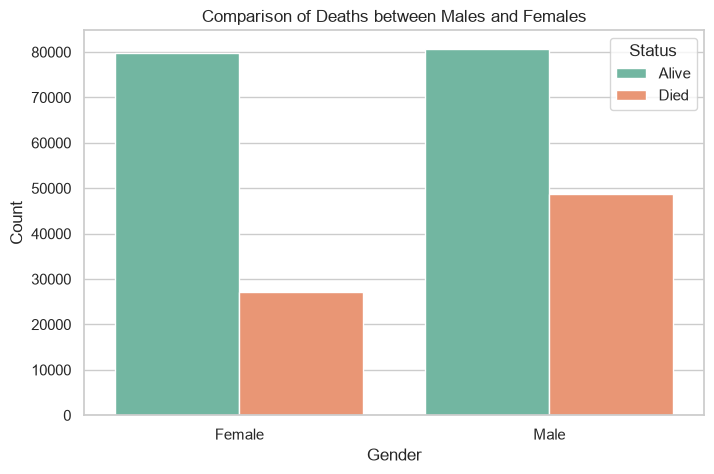

In [26]:
# Set the visualization style
sns.set_theme(style="whitegrid")

# Create a count plot for gender vs death status
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='SEX', hue='IS_DIED', palette='Set2')

# Add title and labels
plt.title('Comparison of Deaths between Males and Females')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.legend(title='Status', labels=['Alive', 'Died'])

# Show the plot
plt.show()

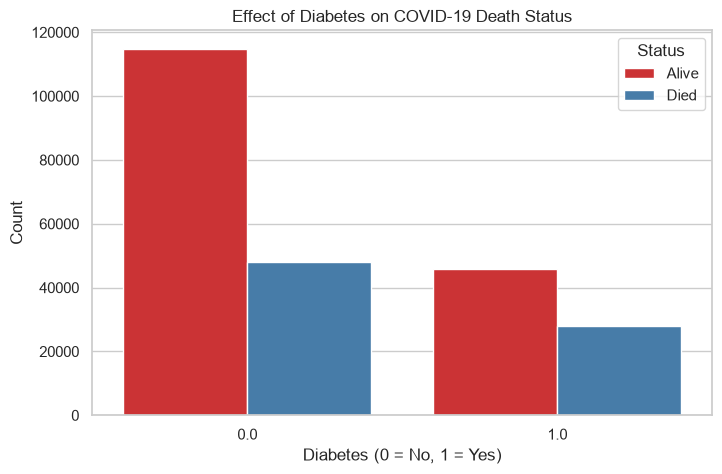

In [27]:
# Create a count plot for Diabetes vs Death status
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='DIABETES', hue='IS_DIED', palette='Set1')

# Add title and labels
plt.title('Effect of Diabetes on COVID-19 Death Status')
plt.xlabel('Diabetes (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.legend(title='Status', labels=['Alive', 'Died'])

# Show the plot
plt.show()

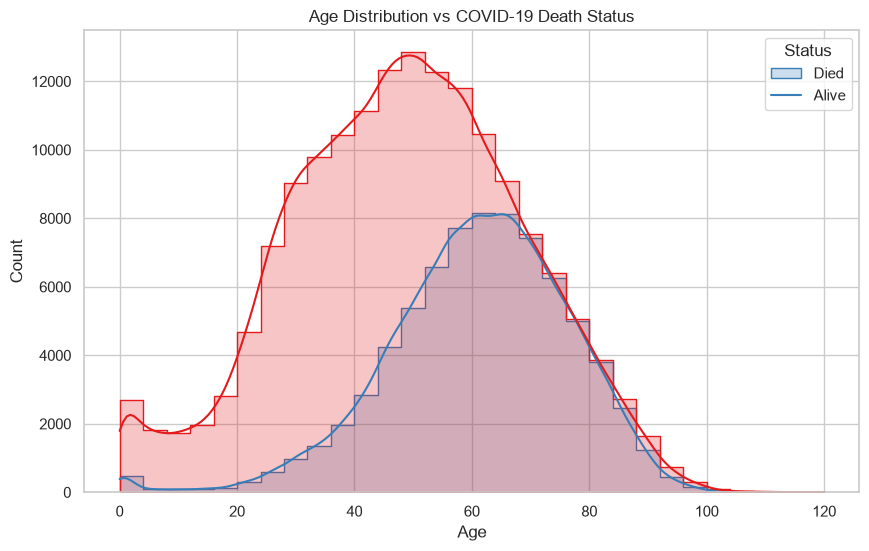

In [28]:
# Create a histogram and KDE plot for Age distribution by Death status
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='AGE', hue='IS_DIED', kde=True, bins=30, palette='Set1', element="step")

# Add title and labels
plt.title('Age Distribution vs COVID-19 Death Status')
plt.xlabel('Age')
plt.ylabel('Count')
plt.legend(title='Status', labels=['Died', 'Alive'])

# Show the plot
plt.show()

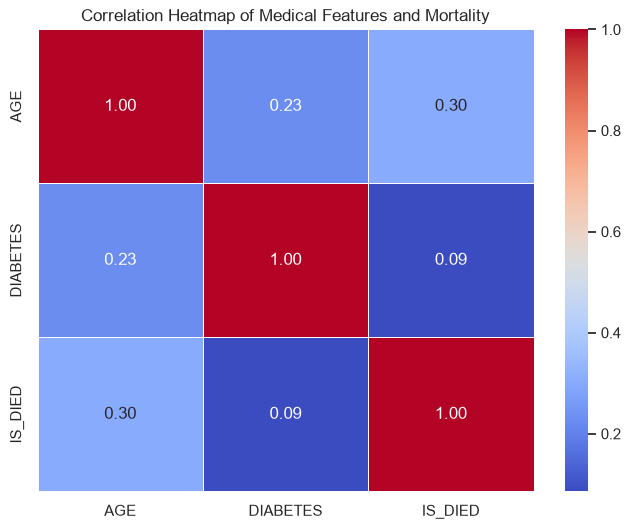

In [29]:
# Select numerical columns for correlation (excluding SEX)
numerical_cols = ['AGE', 'DIABETES', 'IS_DIED']

# Calculate correlation matrix
corr_matrix = df[numerical_cols].corr()

# Plot the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)

# Add title
plt.title('Correlation Heatmap of Medical Features and Mortality')

# Show the plot
plt.show()

In [30]:
# Save the cleaned dataframe to a new CSV file
df.to_csv('cleaned_covid_data.csv', index=False)